# 08 · Conformal referral and fairness audit (SecondLook extras)

Two questions a regulator or credit committee will ask about any scoring model:

1. **"How sure is the model?"** A score of 12% is a best guess. When the data cannot tell whether a loan is
   profitable, SecondLook should **refer** the case to an underwriter instead of auto-deciding it.
2. **"Is it fair?"** Gender and age are never model inputs, but decisions can still differ across groups through
   other features. We audit approval rates by gender and age band, and measure what it costs to close the gaps.

We use the production SecondLook model from notebook 03 (the one behind the explanations and letters).

**Data hygiene:** the uncertainty methods are fit on the `calib` split, which the model never trained on. The isotonic
calibrator *was* fit on `calib`, so the uncertainty methods use the model's **raw** scores there; per-group cutoffs are
fit on `valid`; everything is measured on `test`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

from secondlook.config import EXCLUDED_INPUTS, FIGURES_DIR, MODELS_DIR, PROCESSED_DIR, TARGET_COL
from secondlook.conformal import (assign_zones, bin_edges, binned_intervals, class_conditional_thresholds, decide,
                                marginal_threshold, prediction_sets, set_decision)
from secondlook.fairness import (age_band, apply_thresholds, blend_thresholds, equal_opportunity_gap, group_report,
                               parity_thresholds, portfolio_profit)
from secondlook.features import load_features
from secondlook.modeling import ProfitAssumptions, bootstrap_auc_diff, load_bundle, prepare, train_lightgbm
from secondlook.reject_inference import approval_at_bad_rate

sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8C8C8C"
ZONE_COLORS = {"approve": GREEN, "refer": ORANGE, "decline": RED}
pct = plt.matplotlib.ticker.PercentFormatter(1.0)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
bundle = load_bundle("secondlook_lgbm")
meta = json.loads((MODELS_DIR / "secondlook_lgbm_meta.json").read_text())
CUTOFF = meta["risk_appetite"]["cutoff"]          # calibrated PD cutoff for a 5% default rate (notebook 03)
econ = ProfitAssumptions(**meta["profit_assumptions"])
BREAKEVEN = econ.breakeven_pd

df = prepare(load_features())
for c in EXCLUDED_INPUTS:  # not model inputs, but section 5 retrains with them for comparison
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype("category")
df["raw"] = bundle["model"].predict_proba(df[bundle["columns"]])[:, 1]
df["p"] = bundle["calibrator"].predict(df["raw"])
RAW_CUTOFF = df.loc[df["p"] <= CUTOFF, "raw"].max()   # same decisions on the raw scale (isotonic is monotone)
df["approve"] = df["raw"] <= RAW_CUTOFF
df["age_band"] = age_band(df["AGE_YEARS"]).astype(str)
df["gender"] = df["CODE_GENDER"].astype(str).map({"F": "female", "M": "male"})

va, ca, te = (df[df["split"] == s] for s in ["valid", "calib", "test"])
print(f"Cutoff: approve if predicted default <= {CUTOFF:.3f}; break-even default rate {BREAKEVEN:.1%}")
print(f"calib {len(ca):,} applicants, test {len(te):,}; test approval rate {te['approve'].mean():.1%}")

Cutoff: approve if predicted default <= 0.158; break-even default rate 13.3%
calib 30,752 applicants, test 46,126; test approval rate 87.9%


## 1. Conformal prediction sets: what outcomes can we rule out?

**Split conformal prediction** turns any score into a *set* of plausible outcomes with a guaranteed coverage:
on new applicants, the set contains the true outcome at least 90% of the time (for `alpha = 0.1`), with no assumption
about the model beyond the data being exchangeable. A set `{repay}` means approve, `{default}` decline, and
`{repay, default}` means the model cannot rule either out: **refer**.

There is a trap with imbalanced data. Standard (marginal) conformal guarantees 90% coverage *on average*, and since
92% of applicants repay, it can hit the target while failing defaulters. The **class-conditional** (Mondrian) version
calibrates repayers and defaulters separately, so the guarantee holds for both.

In [3]:
ALPHA = 0.10
rows = {}
q = marginal_threshold(ca[TARGET_COL], ca["raw"], ALPHA)
has_repay, has_default = te["raw"] <= q, (1 - te["raw"]) <= q
rows["Marginal conformal"] = (has_repay, has_default)
q0, q1 = class_conditional_thresholds(ca[TARGET_COL], ca["raw"], ALPHA)
rows["Class-conditional conformal"] = prediction_sets(te["raw"], q0, q1)

y_te = te[TARGET_COL].to_numpy()
summary = {}
for name, (r, d) in rows.items():
    r, d = np.asarray(r), np.asarray(d)
    covered = np.where(y_te == 1, d, r)
    dec = pd.Series(set_decision(r, d))
    summary[name] = {"coverage, all": covered.mean(), "coverage, repayers": covered[y_te == 0].mean(),
                     "coverage, defaulters": covered[y_te == 1].mean(),
                     **{f"share {k}": dec.eq(k).mean() for k in ["approve", "decline", "refer"]}}
pd.DataFrame(summary).T.style.format("{:.1%}")

,"coverage, all","coverage, repayers","coverage, defaulters",share approve,share decline,share refer
Marginal conformal,90.0%,97.9%,0.4%,96.7%,0.1%,3.2%
Class-conditional conformal,90.2%,90.3%,89.2%,40.2%,12.1%,47.6%


,target coverage,"coverage, repayers","coverage, defaulters",refer,decline
alpha,,,,,
0.050000,95.0%,95.0%,94.1%,65.4%,6.8%
0.100000,90.0%,90.3%,89.2%,47.6%,12.1%
0.150000,85.0%,85.1%,84.6%,33.1%,17.9%
0.200000,80.0%,80.2%,79.4%,20.2%,23.0%
0.250000,75.0%,75.3%,75.0%,8.6%,28.0%
0.300000,70.0%,70.5%,70.2%,1.2%,31.7%


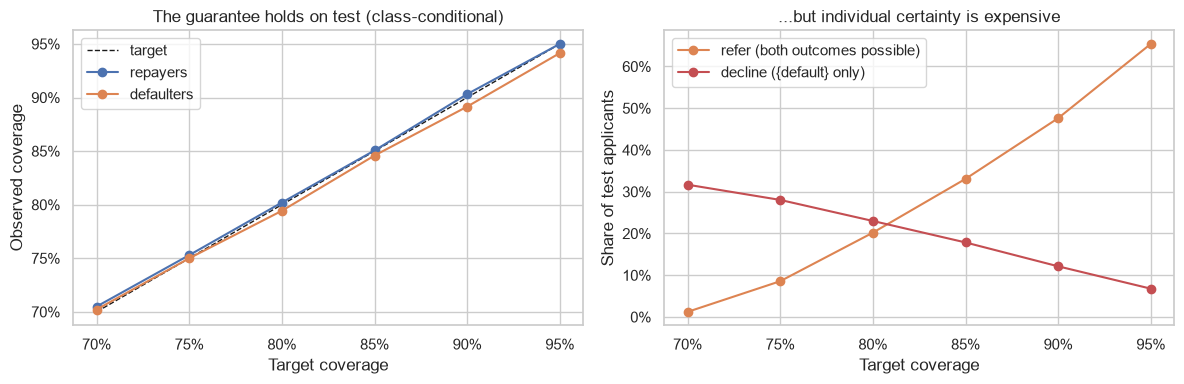

In [4]:
alphas = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
sweep = []
for a in alphas:
    r, d = prediction_sets(te["raw"], *class_conditional_thresholds(ca[TARGET_COL], ca["raw"], a))
    dec = pd.Series(set_decision(r, d))
    sweep.append({"alpha": a, "target coverage": 1 - a,
                  "coverage, repayers": r[y_te == 0].mean(), "coverage, defaulters": d[y_te == 1].mean(),
                  "refer": dec.eq("refer").mean(), "decline": dec.eq("decline").mean()})
sweep = pd.DataFrame(sweep).set_index("alpha")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(sweep["target coverage"], sweep["target coverage"], "k--", lw=1, label="target")
axes[0].plot(sweep["target coverage"], sweep["coverage, repayers"], "o-", color=BLUE, label="repayers")
axes[0].plot(sweep["target coverage"], sweep["coverage, defaulters"], "o-", color=ORANGE, label="defaulters")
axes[0].set(title="The guarantee holds on test (class-conditional)", xlabel="Target coverage", ylabel="Observed coverage")
axes[0].xaxis.set_major_formatter(pct); axes[0].yaxis.set_major_formatter(pct); axes[0].legend()
axes[1].plot(sweep["target coverage"], sweep["refer"], "o-", color=ORANGE, label="refer (both outcomes possible)")
axes[1].plot(sweep["target coverage"], sweep["decline"], "o-", color=RED, label="decline ({default} only)")
axes[1].set(title="...but individual certainty is expensive", xlabel="Target coverage", ylabel="Share of test applicants")
axes[1].xaxis.set_major_formatter(pct); axes[1].yaxis.set_major_formatter(pct); axes[1].legend()
savefig("27_conformal_sets")
sweep.style.format("{:.1%}")

**Reading this:** the guarantee works exactly as promised, for repayers *and* defaulters. But at 90% coverage almost
half of applicants get `{repay, default}`. With an AUC of 0.77, the model ranks risk well but cannot say *which*
individuals will default; nobody can. And a `{default}` set does not mean the applicant will default; it means
"repaying cannot be ruled in at this confidence".

Per-applicant certainty is the wrong target for lending. A lender does not need to know whether *this* person will
default; it needs to know whether lending to people *like this* is profitable. That is section 2.

## 2. Decision-level referral: is lending here profitable?

A loan is profitable in expectation when the default rate is below the **break-even rate**
(margin / (margin + loss given default) = 13.3% under notebook 03's assumptions). So:

1. Split the score into 20 equal-size bins, with bin edges fixed on `valid`.
2. On `calib`, compute each bin's default rate with a **Clopper-Pearson interval**, Bonferroni-adjusted so all 20
   intervals hold *simultaneously* with 95% confidence (exact, distribution-free, finite-sample).
3. **Approve** bins whose whole interval is below break-even, **decline** bins whose whole interval is above it,
   **refer** the bins in between: there, the data cannot tell whether lending makes or loses money.

,share,default_rate,thin_file_share
zone,,,
approve,75.0%,4.1%,12.5%
refer,10.1%,13.0%,19.6%
decline,14.9%,25.0%,19.8%


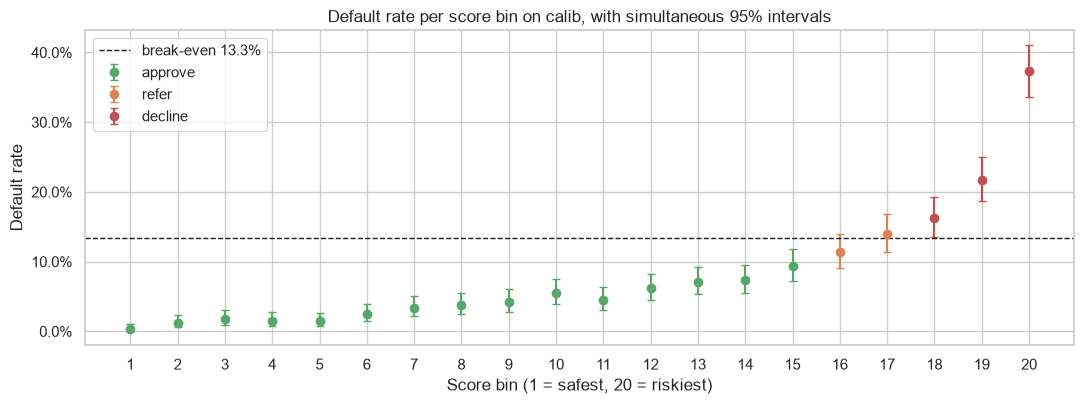

In [5]:
N_BINS = 20
edges = bin_edges(va["raw"], N_BINS)
zones = assign_zones(binned_intervals(ca[TARGET_COL], ca["raw"], edges, confidence=0.95), BREAKEVEN)
te = te.assign(zone=decide(te["raw"], zones))

fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(N_BINS) + 1
for z, color in ZONE_COLORS.items():
    m = (zones["zone"] == z).to_numpy()
    ax.errorbar(x[m], zones["default_rate"][m], yerr=[(zones["default_rate"] - zones["low"])[m], (zones["high"] - zones["default_rate"])[m]],
                fmt="o", color=color, capsize=3, label=z)
ax.axhline(BREAKEVEN, color="k", ls="--", lw=1, label=f"break-even {BREAKEVEN:.1%}")
ax.set(title="Default rate per score bin on calib, with simultaneous 95% intervals",
       xlabel="Score bin (1 = safest, 20 = riskiest)", ylabel="Default rate", xticks=x)
ax.yaxis.set_major_formatter(pct); ax.legend()
savefig("28_referral_zones")

out = te.groupby("zone").agg(share=("zone", "size"), default_rate=(TARGET_COL, "mean"), thin_file_share=("THIN_FILE", "mean"))
out["share"] /= len(te)
out.loc[["approve", "refer", "decline"]].style.format("{:.1%}")

In [6]:
by_seg = pd.crosstab(te["THIN_FILE"].map({0: "has bureau history", 1: "thin-file"}), te["zone"], normalize="index")
print("Decision mix by segment (test):")
display(by_seg[["approve", "refer", "decline"]].style.format("{:.1%}"))

sens = []
for nb in [10, 20, 40]:
    z = assign_zones(binned_intervals(ca[TARGET_COL], ca["raw"], bin_edges(va["raw"], nb)), BREAKEVEN)
    d = pd.Series(decide(te["raw"], z), index=te.index)
    sens.append({"bins": nb, **{k: d.eq(k).mean() for k in ["approve", "refer", "decline"]},
                 "default rate, referred": te.loc[d.eq("refer"), TARGET_COL].mean() if d.eq("refer").any() else np.nan})
print("Sensitivity to the number of bins (finer bins = wider intervals = more referrals):")
pd.DataFrame(sens).set_index("bins").style.format("{:.1%}")

Decision mix by segment (test):


zone,approve,refer,decline
THIN_FILE,,,
has bureau history,76.6%,9.5%,13.9%
thin-file,65.6%,13.8%,20.6%


Sensitivity to the number of bins (finer bins = wider intervals = more referrals):


,approve,refer,decline,"default rate, referred"
bins,,,,
10,80.0%,10.1%,9.9%,15.3%
20,75.0%,10.1%,14.9%,13.0%
40,72.5%,17.6%,9.9%,13.7%


**Reading this:** about 10% of applicants land in the referral zone, and their realised default rate on test sits
almost exactly on break-even: auto-approving them would be a coin flip on profit, auto-declining them would turn away
mostly good borrowers. This is the right job for a human underwriter, who can ask for payslips or bank statements.

Thin-file applicants are referred more often than applicants with bureau history: where the model has less to go on,
SecondLook says so and hands over, instead of quietly declining.

## 3. Fairness audit: gender and age

Measured at the production cutoff on `test`. Gender and age are not model inputs. The metrics:

- **Approval rate**: equal rates across groups is *demographic parity*.
- **Good-borrower approval**: the share of applicants who went on to repay who were approved. Equal rates is
  *equal opportunity*: creditworthy people are treated alike regardless of group.
- **Default rate among approved** and **mean predicted vs observed default**: does a score mean the same risk in
  every group (*calibration within groups*)?

In [7]:
audit = {}
for col in ["gender", "age_band"]:
    t = te[te[col].notna() & (te[col] != "nan")]
    audit[col] = group_report(t[TARGET_COL], t["approve"], t[col], p=t["p"])
    print(f"\n{col}: equal-opportunity gap {equal_opportunity_gap(t[TARGET_COL], t['approve'], t[col]):.1%}")
    display(audit[col].style.format({c: "{:.1%}" for c in audit[col].columns if c != "applicants"} | {"applicants": "{:,}"}))


gender: equal-opportunity gap 4.9%


,applicants,default rate,approval rate,good-borrower approval,default rate among approved,mean predicted default
female,"30,314",7.1%,90.0%,92.0%,5.0%,7.3%
male,"15,812",9.9%,84.0%,87.1%,6.6%,9.3%
overall,"46,126",8.1%,87.9%,90.3%,5.5%,8.0%



age_band: equal-opportunity gap 16.8%


,applicants,default rate,approval rate,good-borrower approval,default rate among approved,mean predicted default
"[18, 30)","6,672",11.1%,76.8%,80.3%,7.0%,12.0%
"[30, 40)","12,514",9.6%,85.2%,88.3%,6.3%,9.0%
"[40, 50)","11,610",7.6%,90.0%,92.2%,5.3%,7.3%
"[50, 60)","10,149",6.3%,91.9%,93.5%,4.6%,6.6%
"[60, 70)","5,181",4.8%,96.4%,97.1%,4.2%,4.8%
overall,"46,126",8.1%,87.9%,90.3%,5.5%,8.0%


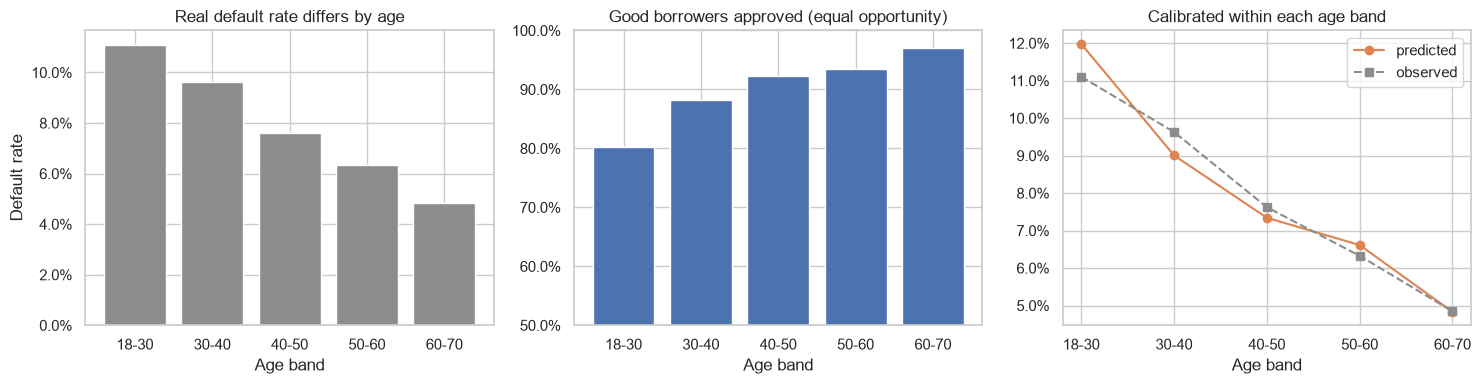

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
a = audit["age_band"].drop(index="overall")
labels = [s.replace("[", "").replace(")", "").replace(", ", "-") for s in a.index]
axes[0].bar(labels, a["default rate"], color=GREY)
axes[0].set(title="Real default rate differs by age", ylabel="Default rate", xlabel="Age band")
axes[1].bar(labels, a["good-borrower approval"], color=BLUE)
axes[1].set(title="Good borrowers approved (equal opportunity)", ylim=(0.5, 1), xlabel="Age band")
axes[2].plot(labels, a["mean predicted default"], "o-", color=ORANGE, label="predicted")
axes[2].plot(labels, a["default rate"], "s--", color=GREY, label="observed")
axes[2].set(title="Calibrated within each age band", xlabel="Age band"); axes[2].legend()
for ax in axes: ax.yaxis.set_major_formatter(pct)
savefig("29_fairness_age")

**Reading this:** the model is well calibrated in every group: a predicted 10% means about 10% whether you are 25 or 55,
male or female. But younger applicants and men really do default more in this data, so at one cutoff a creditworthy
25-year-old is less likely to be approved than a creditworthy 55-year-old. When base rates differ, *calibration* and
*equal opportunity* cannot both hold exactly (Kleinberg et al., 2016; Chouldechova, 2017); a lender has to choose,
and should know the price.

### Removing gender and age from the inputs is not enough
How well can the model's own inputs predict the protected attributes? If well, the model *could* use proxies.
(These are the production inputs, which since this audit exclude `NAME_FAMILY_STATUS`, `CNT_CHILDREN` and
`EMPLOYED_AGE_RATIO`; see section 5.)

In [9]:
cols = bundle["columns"]
tr = df[df["split"] == "train"]
proxy = {}
for name, target in [("gender (male)", lambda d: (d["gender"] == "male").astype(int)),
                     ("age under 30", lambda d: (d["AGE_YEARS"] < 30).astype(int))]:
    m = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.6, verbose=-1, random_state=0)
    m.fit(tr[cols], target(tr))
    proxy[name] = roc_auc_score(target(te), m.predict_proba(te[cols])[:, 1])
    imp = pd.Series(m.booster_.feature_importance("gain"), index=cols).nlargest(4)
    print(f"{name}: AUC {proxy[name]:.3f}; strongest proxies: {', '.join(imp.index)}")

gender (male): AUC 0.900; strongest proxies: OCCUPATION_TYPE, OWN_CAR_AGE, ORGANIZATION_TYPE, EXT_SOURCE_1


age under 30: AUC 0.962; strongest proxies: YEARS_SINCE_ID_CHANGE, YEARS_EMPLOYED, EXT_SOURCE_1, YEARS_SINCE_REGISTRATION


In [10]:
# Why EMPLOYED_AGE_RATIO was removed: it is YEARS_EMPLOYED / AGE_YEARS (notebook 02), so dividing the two
# gives back age exactly for everyone with a job.
emp = tr[(tr["EMPLOYED_AGE_RATIO"] > 0) & tr["EMPLOYED_AGE_RATIO"].notna()]
recovered = emp["YEARS_EMPLOYED"] / emp["EMPLOYED_AGE_RATIO"]
print(f"Age recovered from YEARS_EMPLOYED / EMPLOYED_AGE_RATIO: correlation {np.corrcoef(recovered, emp['AGE_YEARS'])[0, 1]:.4f} "
      f"({len(emp) / len(tr):.0%} of applicants)")
cols_old = cols + ["EMPLOYED_AGE_RATIO"]
m = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.6, verbose=-1, random_state=0)
m.fit(tr[cols_old], (tr["AGE_YEARS"] < 30).astype(int))
proxy["age under 30, if EMPLOYED_AGE_RATIO were an input"] = roc_auc_score((te["AGE_YEARS"] < 30).astype(int), m.predict_proba(te[cols_old])[:, 1])
print(f"Predicting age under 30 with that ratio added back: AUC {proxy['age under 30, if EMPLOYED_AGE_RATIO were an input']:.3f}")

Age recovered from YEARS_EMPLOYED / EMPLOYED_AGE_RATIO: correlation 1.0000 (82% of applicants)


Predicting age under 30 with that ratio added back: AUC 0.999


Model inputs predict both attributes far better than chance (gender mostly through occupation, employer type and car
ownership; age through career length), so dropping a column does not make a model blind to it. The first version of
this model also had `EMPLOYED_AGE_RATIO`, which let it reconstruct age **exactly** for employed applicants; this audit
is why it was removed. Age stays strongly predictable from career length, which is why we
**audit outcomes** rather than trusting the input list.

## 4. Closing the age gap: what does it cost?

We mitigate the **age** gap (the larger one) toward equal opportunity, two ways:

- **Post-processing:** a separate cutoff per age band so good borrowers are approved at the same rate (the idea behind
  Fairlearn's `ThresholdOptimizer`), fit on `valid`. Blending from one cutoff (strength 0) to full parity (strength 1)
  traces the trade-off. *Caveat:* it uses age **at decision time**, which is disparate treatment and generally not
  allowed in lending (e.g. US ECOA/Regulation B); shown as a benchmark.
- **In-processing:** Fairlearn's `ExponentiatedGradient` retrains LightGBM under an equal-opportunity constraint with
  the cost of each mistake set by our cutoff. Age is used **only during training**; the final model sees the normal inputs.

Cost is measured as expected profit on test (notebook 03's economics) relative to the unmitigated policy.

In [11]:
post = []
raw_th = parity_thresholds(va[TARGET_COL], va["raw"], va["age_band"], RAW_CUTOFF)
base_profit = portfolio_profit(te[TARGET_COL], te["approve"], te["AMT_CREDIT"], econ.margin, econ.lgd)
for s in [0, 0.25, 0.5, 0.75, 1.0]:
    a = apply_thresholds(te["raw"], te["age_band"], blend_thresholds(raw_th, RAW_CUTOFF, s), RAW_CUTOFF)
    post.append({"method": "Per-group cutoffs", "setting": f"strength {s:.2f}",
                 "equal-opportunity gap": equal_opportunity_gap(te[TARGET_COL], a, te["age_band"]),
                 "approval rate": a.mean(), "default rate among approved": te.loc[a, TARGET_COL].mean(),
                 "profit vs unmitigated": portfolio_profit(te[TARGET_COL], a, te["AMT_CREDIT"], econ.margin, econ.lgd) / base_profit - 1})
post = pd.DataFrame(post)
post.style.format({c: "{:.1%}" for c in post.columns if c not in ["method", "setting"]} | {"profit vs unmitigated": "{:+.1%}"})

,method,setting,equal-opportunity gap,approval rate,default rate among approved,profit vs unmitigated
0,Per-group cutoffs,strength 0.00,16.8%,87.9%,5.5%,+0.0%
1,Per-group cutoffs,strength 0.25,12.5%,88.2%,5.6%,-0.1%
2,Per-group cutoffs,strength 0.50,8.5%,88.3%,5.6%,+0.2%
3,Per-group cutoffs,strength 0.75,4.8%,88.2%,5.6%,-0.2%
4,Per-group cutoffs,strength 1.00,0.5%,87.9%,5.6%,-0.7%


In [12]:
from fairlearn.reductions import ErrorRate, ExponentiatedGradient, TruePositiveRateParity

RUN_EG = False  # True reruns the three fits (about 4 min); False reuses saved results
eg_path = PROCESSED_DIR / "fairness_expgrad.json"
c = CUTOFF  # cost of approving a defaulter vs declining a good borrower puts the decision boundary at the cutoff
sample = tr.sample(60_000, random_state=0)
y_good = 1 - sample[TARGET_COL]  # Fairlearn's positive class = good borrower, positive prediction = approve

def small_lgbm():
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.6, verbose=-1, random_state=0)

def evaluate(name, approve_prob):
    a = np.asarray(approve_prob, dtype=float)
    return {"method": "ExponentiatedGradient", "setting": name,
            "equal-opportunity gap": equal_opportunity_gap(te[TARGET_COL], a, te["age_band"]),
            "approval rate": a.mean(), "default rate among approved": (a * te[TARGET_COL]).sum() / a.sum(),
            "profit": portfolio_profit(te[TARGET_COL], a, te["AMT_CREDIT"], econ.margin, econ.lgd)}

if RUN_EG or not eg_path.exists():
    eg_rows = []
    t = time.time()
    weights = np.where(sample[TARGET_COL] == 1, 1 - c, c)  # same costs, no constraint
    base = small_lgbm().fit(sample[cols], y_good, sample_weight=weights)
    eg_rows.append(evaluate("no constraint", base.predict_proba(te[cols])[:, 1] >= 0.5))
    for eps in [0.05, 0.02]:
        eg = ExponentiatedGradient(small_lgbm(), TruePositiveRateParity(), objective=ErrorRate(costs={"fp": 1 - c, "fn": c}),
                                   eps=eps, max_iter=15)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            eg.fit(sample[cols], y_good, sensitive_features=sample["age_band"])
        eg_rows.append(evaluate(f"constraint eps={eps}", eg._pmf_predict(te[cols])[:, 1]))
    eg_path.write_text(json.dumps(eg_rows, indent=2))
    print(f"ExponentiatedGradient runs took {(time.time() - t) / 60:.1f} min")
eg_res = pd.DataFrame(json.loads(eg_path.read_text()))
eg_res["profit vs unmitigated"] = eg_res["profit"] / eg_res.loc[0, "profit"] - 1
eg_res = eg_res.drop(columns="profit")
eg_res.style.format({c: "{:.1%}" for c in eg_res.columns if c not in ["method", "setting"]} | {"profit vs unmitigated": "{:+.1%}"})

ExponentiatedGradient runs took 4.5 min


,method,setting,equal-opportunity gap,approval rate,default rate among approved,profit vs unmitigated
0,ExponentiatedGradient,no constraint,15.4%,89.5%,5.8%,+0.0%
1,ExponentiatedGradient,constraint eps=0.05,3.7%,90.2%,6.0%,-0.9%
2,ExponentiatedGradient,constraint eps=0.02,5.3%,90.2%,6.0%,-1.0%


`ExponentiatedGradient` returns a *randomised* mix of models, so approvals are probabilities; it is compared with an
unconstrained model trained the same way (same 60,000-applicant sample, same costs), not with the full production model.

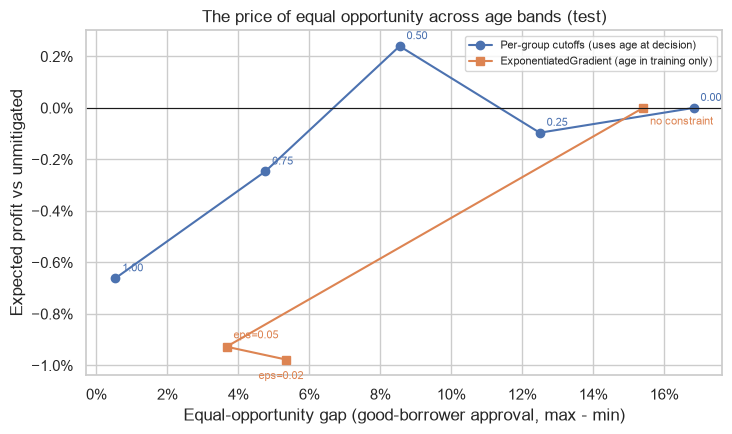

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(post["equal-opportunity gap"], post["profit vs unmitigated"], "o-", color=BLUE, label="Per-group cutoffs (uses age at decision)")
for _, r in post.iterrows():
    ax.annotate(r["setting"].replace("strength ", ""), (r["equal-opportunity gap"], r["profit vs unmitigated"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8, color=BLUE)
ax.plot(eg_res["equal-opportunity gap"], eg_res["profit vs unmitigated"], "s-", color=ORANGE, label="ExponentiatedGradient (age in training only)")
for (_, r), off in zip(eg_res.iterrows(), [(5, -12), (5, 6), (-20, -14)]):
    ax.annotate(r["setting"].replace("constraint ", ""), (r["equal-opportunity gap"], r["profit vs unmitigated"]),
                textcoords="offset points", xytext=off, fontsize=8, color=ORANGE)
ax.axhline(0, color="k", lw=0.8)
ax.set(title="The price of equal opportunity across age bands (test)", xlabel="Equal-opportunity gap (good-borrower approval, max - min)",
       ylabel="Expected profit vs unmitigated")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=1)); ax.legend(fontsize=8)
savefig("30_fairness_tradeoff")

## 5. What did removing family status, children and the age ratio cost?

The first version of this audit found three inputs a lender should not use: `NAME_FAMILY_STATUS` and `CNT_CHILDREN`
(marital and family status are protected in several jurisdictions, e.g. marital status under US ECOA) and
`EMPLOYED_AGE_RATIO` (an exact copy of age, above). They are now excluded in `config.EXCLUDED_INPUTS`, and notebooks
03-07 were rerun without them. Here we retrain a model **with** them, same settings, to measure what removing them cost.

In [14]:
cols_with = cols + EXCLUDED_INPUTS
va_all = df[df["split"] == "valid"]
t = time.time()
model_with = train_lightgbm(tr[cols_with], tr[TARGET_COL], va_all[cols_with], va_all[TARGET_COL])
print(f"Retrained with {EXCLUDED_INPUTS} in {time.time() - t:.0f}s ({model_with.best_iteration_} trees)")
p_with = model_with.predict_proba(te[cols_with])[:, 1]
p_prod = te["raw"].to_numpy()
thin = te["THIN_FILE"].to_numpy().astype(bool)
abl = pd.DataFrame({name: {"AUC, all": roc_auc_score(y_te, p), "AUC, thin-file": roc_auc_score(y_te[thin], p[thin]),
                           **{f"{k} @ 5%": v for k, v in approval_at_bad_rate(y_te, p, thin, 0.05).items()}}
                    for name, p in [("With the three inputs", p_with), ("SecondLook production (without)", p_prod)]}).T
display(abl.style.format({c: "{:.4f}" if "AUC" in c else "{:.1%}" for c in abl.columns}))
ci = bootstrap_auc_diff(y_te, p_with, p_prod, {"all": np.ones(len(y_te), bool), "thin-file": thin})
print("AUC change from removing them (paired bootstrap):")
ci.style.format({"mean": "{:+.4f}", "low": "{:+.4f}", "high": "{:+.4f}"})

Retrained with ['NAME_FAMILY_STATUS', 'CNT_CHILDREN', 'EMPLOYED_AGE_RATIO'] in 35s (711 trees)


,"AUC, all","AUC, thin-file",approval_rate @ 5%,thin_approval_rate @ 5%
With the three inputs,0.7760,0.7558,84.1%,78.0%
SecondLook production (without),0.7756,0.7549,84.1%,78.1%


AUC change from removing them (paired bootstrap):


,mean,low,high,significant
segment,,,,
all,-0.0005,-0.0021,+0.0013,False
thin-file,-0.0006,-0.0050,+0.0039,False


In [15]:
results = {
    "conformal_class_conditional_alpha_0.10": pd.DataFrame(summary).T.loc["Class-conditional conformal"].to_dict(),
    "referral_zones": {"bins": N_BINS, "breakeven_pd": BREAKEVEN,
                       "test": out.reset_index().to_dict(orient="records"),
                       "by_segment": by_seg.reset_index().to_dict(orient="records")},
    "fairness_gaps": {col: equal_opportunity_gap(te[TARGET_COL], te["approve"], te[col]) for col in ["gender", "age_band"]},
    "proxy_auc": proxy,
    "mitigation": pd.concat([post, eg_res]).to_dict(orient="records"),
    "removed_inputs": {"columns": EXCLUDED_INPUTS, "metrics": abl.to_dict(orient="index"), "bootstrap": ci.reset_index().to_dict(orient="records")},
}
(PROCESSED_DIR / "conformal_fairness_results.json").write_text(json.dumps(results, indent=2, default=str))
print("Saved data/processed/conformal_fairness_results.json")

Saved data/processed/conformal_fairness_results.json


## Takeaways

**Uncertainty**
- **Conformal prediction sets work as guaranteed.** At a 90% target, the class-conditional version covers 90.3% of
  repayers and 89.2% of defaulters on test. Standard (marginal) conformal also reaches 90% overall, but covers only
  **0.4% of defaulters**: the imbalance trap.
- **But per-applicant certainty is the wrong target for lending:** at 90% coverage, 48% of applicants would be referred.
- **Decision-level referral is practical.** Comparing each score bin's default-rate interval with the 13.3% break-even rate:
  75.0% auto-approve (4.1% default on test), **10.1% refer** (13.0% default, a coin flip on profit) and 14.9% decline (25.0%).
  Thin-file applicants are referred more (13.8% vs 9.5%): where the model knows less, a human decides.

**Fairness**
- **The model is calibrated in every group**, so a score means the same risk for everyone. But real default rates differ
  (under 30: 11.1%, 60 and over: 4.8%), so at one cutoff, equal opportunity is not met: good borrowers under 30 are approved
  80.3% of the time vs 97.1% for 60 and over (a **16.8-point gap**; gender gap 4.9 points).
- **Leaving gender and age out of the inputs does not hide them.** The inputs predict gender with AUC 0.90 and "under 30"
  with AUC 0.96, through occupation, car ownership and career length. The first model version also had `EMPLOYED_AGE_RATIO`,
  which with `YEARS_EMPLOYED` gives back age exactly (AUC 0.999); it has been removed.
- **Closing most of the age gap costs about 1% of profit.** Per-group cutoffs close it to 0.5 points for 0.7% of profit,
  but they use age at decision time, which lending law generally forbids. `ExponentiatedGradient` cuts its gap from 15.4
  to 3.7 points for about 0.9% of profit, against its own unconstrained baseline, with age used only in training.
- **Removing family status, number of children and the age ratio cost nothing measurable:** AUC changes by −0.0005
  (95% interval −0.0021 to +0.0013; thin-file −0.0006, not significant).

**Recommendation:** keep those three inputs out (done: `config.EXCLUDED_INPUTS`), route the referral zone to underwriters,
and track the equal-opportunity gap on every model release. Whether to close the age gap, and how far, is a policy choice;
this notebook prices it.